## Polynomial Regression on Boston Housing Dataset

**In this notebook we do a comparative study of Linear Regression and Polynomial Regression accuracy on the Boston Housing Dataset**

This data was originally a part of UCI Machine Learning Repository and has been removed now. This data also ships with the scikit-learn library. 
There are 506 samples and 13 feature variables in this data-set. The objective is to predict the value of prices of the house using the given features.

The description of all the features is given below:

  **CRIM**: Per capita crime rate by town

  **ZN**: Proportion of residential land zoned for lots over 25,000 sq. ft

  **INDUS**: Proportion of non-retail business acres per town

  **CHAS**: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)

  **NOX**: Nitric oxide concentration (parts per 10 million)

  **RM**: Average number of rooms per dwelling

  **AGE**: Proportion of owner-occupied units built prior to 1940

  **DIS**: Weighted distances to five Boston employment centers

  **RAD**: Index of accessibility to radial highways

  **TAX**: Full-value property tax rate per $10,000

  **B**: 1000(Bk - 0.63)², where Bk is the proportion of [people of African American descent] by town

  **LSTAT**: Percentage of lower status of the population

  **MEDV**: Median value of owner-occupied homes in $1000s
  
  
  



I**mport the required Libraries**

In [46]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

**Load the data into pandas dataframe . Load the Boston Housing DataSet from data/boston_house_prices.csv**

In [47]:
df = pd.read_csv('data/boston_house_prices.csv')
df = pd.read_csv('data/boston_house_prices.csv', header=1)
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


**Data preprocessing**

Check for missing values in all the columns

In [48]:
df.isna().sum()  #para revisar cuantos valores faltantes hay en cada columna. 



CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [49]:
df.isna().sum()[df.isna().sum() > 0]   #Para ver solo las columnas que tienen valores faltantes:

Series([], dtype: int64)

**Data Visualization**

In [50]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [51]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


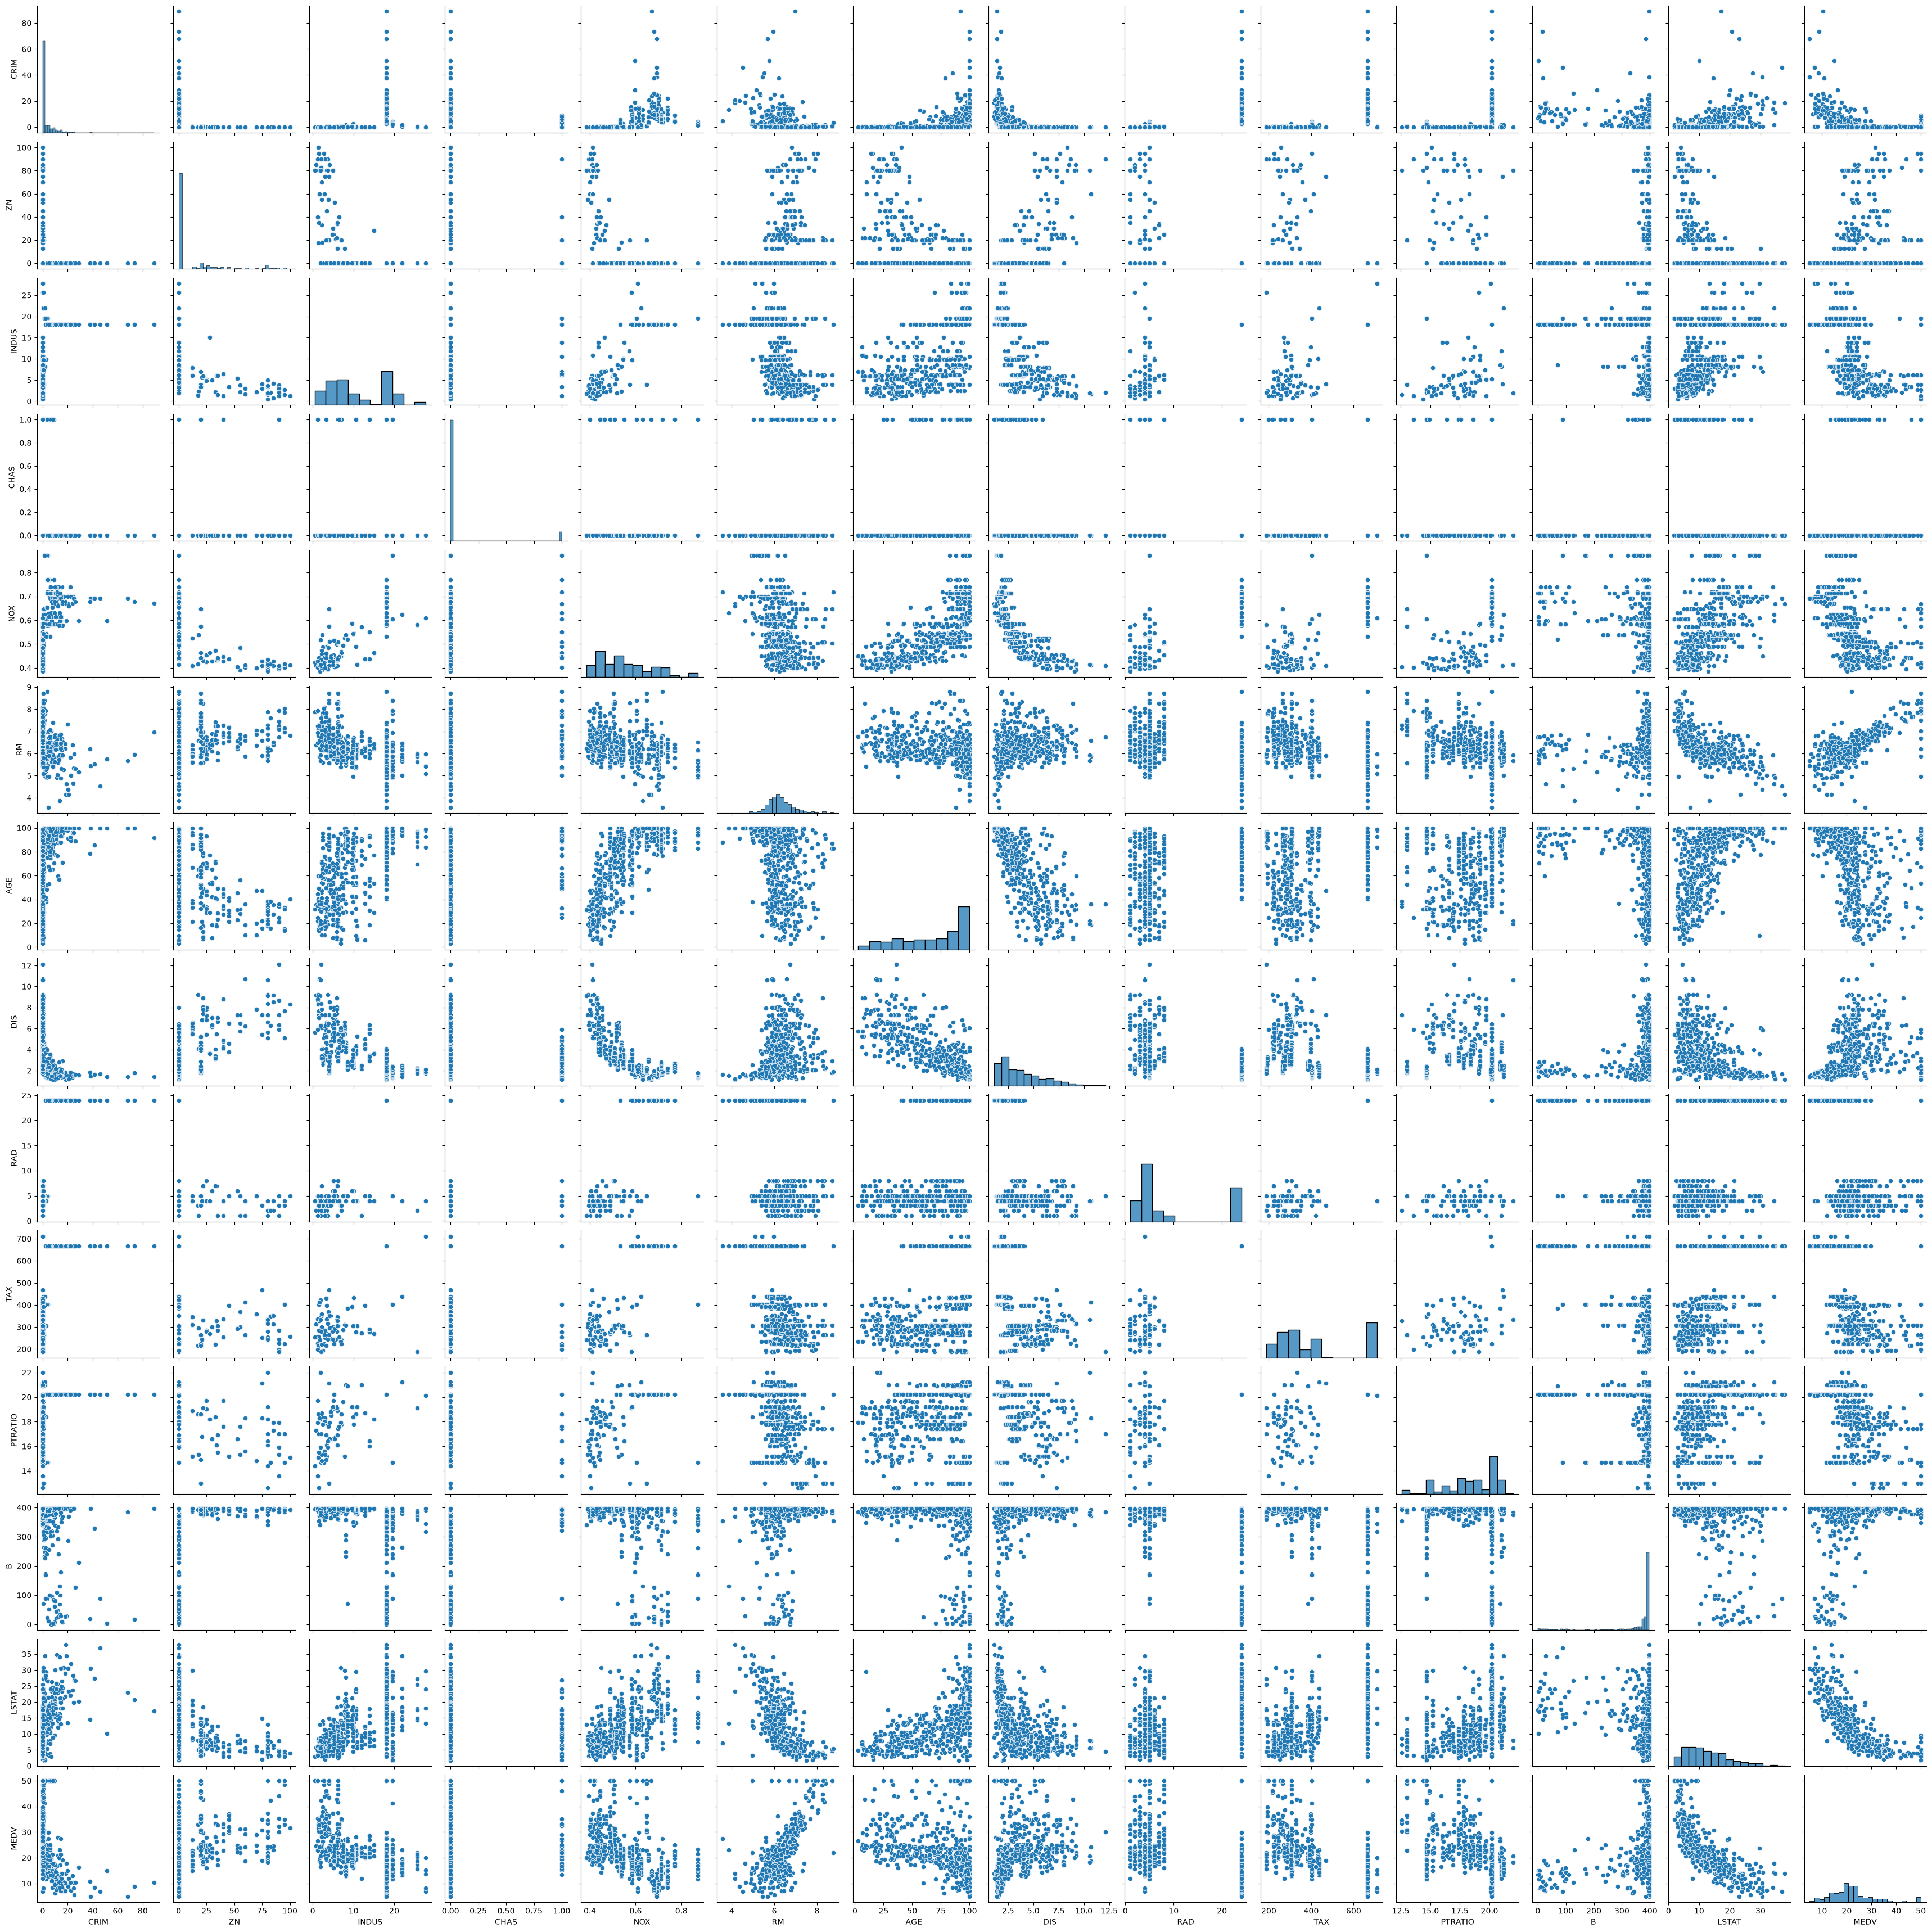

In [52]:

sns.pairplot(df);


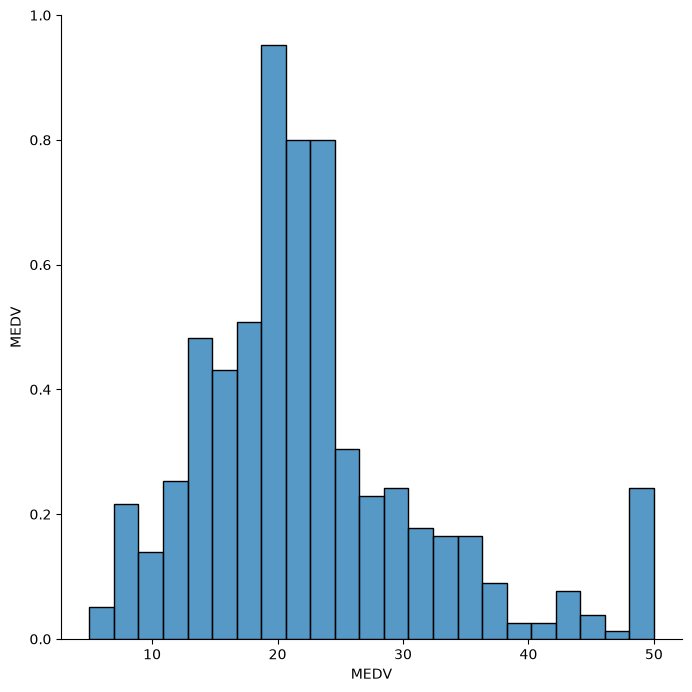

In [53]:
sns.pairplot(df, vars=["MEDV"], height=7)

**Correlation matrix**

Analyze the correlation matrix. Plot a heatmap

* From correlation plot: which are the columns that are more correlated with **MEDV**
* There are two features highly correlated. Identify them and drop one of them in order to avoid multi-colinearity

<Axes: >

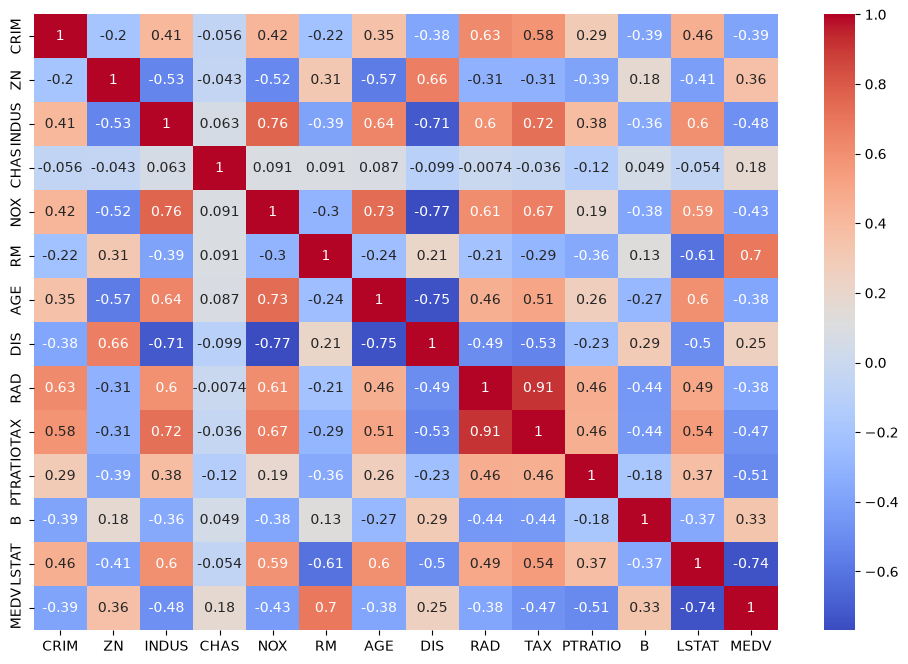

In [54]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

### Draw 2 scatter plots to see the relationship between **MEDV** and **LSTAT** and **RM**

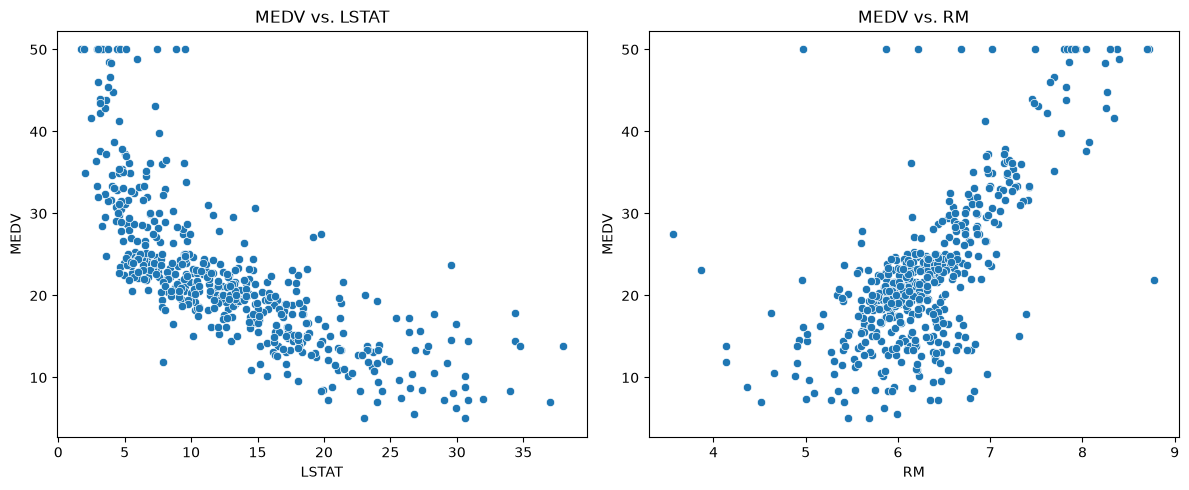

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="LSTAT", y="MEDV", ax=axes[0])
axes[0].set_title("MEDV vs. LSTAT")

sns.scatterplot(data=df, x="RM", y="MEDV", ax=axes[1])
axes[1].set_title("MEDV vs. RM")

plt.tight_layout()
plt.show()



**Prepare the data for training**
Create a dataframe X including **LSTAT** and **RM** columns.
Y should be a pandas series including target values **'MEDV'**


In [56]:
X = df[['LSTAT', 'RM']]  #RM SON LAS HABITACIONES
Y = df['MEDV']     #ESTA VARIABLE ES EL PRECIO

**Split the data into training and testing sets**

Splits the training and test data set in 80% : 20%. Assign random_state to any value. This ensures consistency. Print the sahes of the resulting objects

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=10                      #USO ESTE PARA COMPARAR CON EL EJERCICIO DE CLASE FINAL, PERO NORMALMENTE UTILIZAMOS 42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (404, 2)
X_test: (102, 2)
Y_train: (404,)
Y_test: (102,)


# **Linear Regression**

Build a linear regression model with sklearn LinearRegression.
We'll use Mean Squared error and R2 score to evaluate our model, so be sure to make the needed imports.

Import the necessary functions and train a LinearRegression model

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

model = LinearRegression()
# Entrena el modelo con los datos de entrenamiento
model.fit(X_train, Y_train)

# Predice los valores para los datos de prueba
Y_pred = model.predict(X_test)

# Calcula el error cuadrático medio
print("MSE:", mean_squared_error(Y_test, Y_pred))

# Calcula el coeficiente de determinación R²
print("R²:", r2_score(Y_test, Y_pred))

MSE: 41.402023411523814
R²: 0.604114273522912


**Evaluate the model performance in the training and testing sets**

In [59]:
Y_train_pred = model.predict(X_train)
Y_test_pred = model.predict(X_test)

# Calcula el error cuadrático medio (MSE) y el R² en entrenamiento
print("Training MSE:", mean_squared_error(Y_train, Y_train_pred))
print("Training R²:", r2_score(Y_train, Y_train_pred))
print("Training MAE:", mean_absolute_error(Y_train, Y_train_pred))

print("--------------------------------------------------------")
# Calcula el error cuadrático medio (MSE) y el R² en prueba
print("Testing MSE:", mean_squared_error(Y_test, Y_test_pred))
print("Testing R²:", r2_score(Y_test, Y_test_pred))
print("Testing MAE:", mean_absolute_error(Y_test, Y_test_pred))

Training MSE: 27.98794118547948
Training R²: 0.6363353379616082
Training MAE: 3.7980634226890113
--------------------------------------------------------
Testing MSE: 41.402023411523814
Testing R²: 0.604114273522912
Testing MAE: 4.582645892343417


**Lets see the model performance visually. Let's plot y_test vs y_pred**

Plotting the y_test vs y_pred. Ideally should have been a straight line

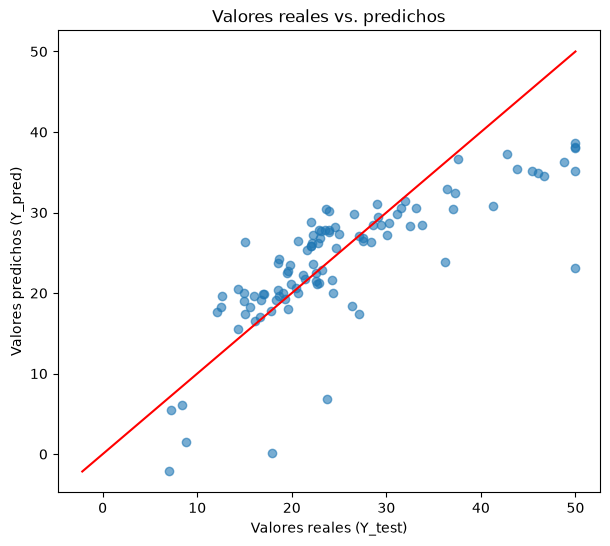

In [60]:
plt.figure(figsize=(7, 6))
plt.scatter(Y_test, Y_test_pred, alpha=0.6)

limite_min = min(Y_test.min(), Y_test_pred.min())
limite_max = max(Y_test.max(), Y_test_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], 'r-')

plt.xlabel('Valores reales (Y_test)')
plt.ylabel('Valores predichos (Y_pred)')
plt.title('Valores reales vs. predichos')
plt.show()

In [61]:
Y_test.min()


np.float64(7.0)

# **Polynomial Regression**

We can see that **LSTAT** doesn't vary exactly in a linear way. Let's apply the Polynomial Regression with **degree 2** and test. 

To generate the higher order degrees, we use PolyniomialFeatures class from sklearn library. 

In [62]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


polynomial = PolynomialFeatures(degree=2)


X_train_poly = polynomial.fit_transform(X_train) # Ajusta y transforma las variables de entrenamiento
X_test_poly = polynomial.transform(X_test) # Transforma las variables de prueba con el mismo ajuste

poly_model = LinearRegression() # Crea el modelo de regresión lineal polinómica
poly_model.fit(X_train_poly, Y_train) # Entrena el modelo con los datos transformados

Y_test_poly_pred = poly_model.predict(X_test_poly) # Predice MEDV para los datos de prueba

print("MSE:", mean_squared_error(Y_test, Y_test_poly_pred))
print("R²:", r2_score(Y_test, Y_test_poly_pred))



MSE: 26.30197973203972
R²: 0.7485007375000432


In [63]:
X_train.shape

(404, 2)

In [64]:
X_train_poly.shape

(404, 6)

Vemos que pasamos de 2 a 6 columnas luego de la transformación.

In [65]:
poly_model_2 = LinearRegression()
poly_model_2.fit(X_train_poly, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0. , 0.33,-15.49, 0.01, -0.23, 1.74]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.73
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[4691.47, 298.04, 149.51, 9.78, 0.98, 0. ]"


**Did the model improve using the Polynomial model?**

In [66]:
# Comparación de modelos
Y_linear_pred = model.predict(X_test)
Y_poly_pred = poly_model.predict(X_test_poly)

print("Lineal    - MSE:", mean_squared_error(Y_test, Y_linear_pred),
      "| R²:", r2_score(Y_test, Y_linear_pred), "| MAE:", mean_absolute_error(Y_test, Y_linear_pred))
print("Polinómico - MSE:", mean_squared_error(Y_test, Y_poly_pred),
      "| R²:", r2_score(Y_test, Y_poly_pred), "| MAE:", mean_absolute_error(Y_test, Y_poly_pred))


Lineal    - MSE: 41.402023411523814 | R²: 0.604114273522912 | MAE: 4.582645892343417
Polinómico - MSE: 26.30197973203972 | R²: 0.7485007375000432 | MAE: 3.542240876057946


**Did the model improve using the Polynomial model with degree 3? Or more?**

In [44]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Ajuste de modelos polinómicos de diferentes grados y evaluación de su desempeño
resultados = []

# For para grados de 2 a 5
for grado in range(2, 6):
    polynomial = PolynomialFeatures(degree=grado, include_bias=False)
    X_train_poly = polynomial.fit_transform(X_train)
    X_test_poly = polynomial.transform(X_test)

# Ajuste del modelo de regresión lineal con las características polinómicas
    modelo = LinearRegression()
    modelo.fit(X_train_poly, Y_train)

# Predicciones y evaluación del modelo
    pred_train = modelo.predict(X_train_poly)
    pred_test = modelo.predict(X_test_poly)

    resultados.append({
        'Grado': grado,
        'MSE train': mean_squared_error(Y_train, pred_train),
        'MSE test': mean_squared_error(Y_test, pred_test),
        'R² train': r2_score(Y_train, pred_train),
        'R² test': r2_score(Y_test, pred_test)
    })
# Resultados en un DataFrame ordenado por Grado
pd.DataFrame(resultados).sort_values('Grado')

,Grado,MSE train,MSE test,R² train,R² test
0,2,19.034384,26.301980,0.752674,0.748501
1,3,17.792073,26.096535,0.768817,0.750465
2,4,18.002700,27.763790,0.766080,0.734523
3,5,18.676927,27.833480,0.757319,0.733857


Esto siguiente es para evaluar un modelo entrenándolo y puntuándolo en varias particiones de los datos.
Prueba tu modelo varias veces con distintas partes de los datos y calcula qué tan bien predice. 
cv=10 significa que hace 10 pruebas. El resultado promedio te da una idea de qué tan bien funciona el modelo. Cuando mas cercano a cero el valor, diriamos que mejor funciona el modelo.

In [68]:
from sklearn.model_selection import cross_val_score

In [72]:
results_cv = cross_val_score(
    LinearRegression(),
    X,
    Y,
    scoring="neg_mean_absolute_error",
    cv=10
)

print(results_cv)
print(results_cv.mean())
print(results_cv.std())



[-2.74282364 -2.66486168 -2.89248316 -5.15153202 -3.9402028  -4.64564316
 -3.82923301 -8.69643448 -6.53638215 -2.94554412]
-4.404514022690067
1.8528516111956586
